# Early stopping vs successive halving after Condensed Nearest Neighbour (CNN)

This notebook asks two questions about CatBoost (`cat`), LightGBM (`lgbm`) and XGBoost
(`xgb`) trained after Condensed Nearest Neighbour undersampling:

1. Does tuning them with **early stopping** (ES) improve their performance compared with
   **successive halving** (SH)?
2. If so, are the boosters trained after CNN now better than the same boosters trained
   on the original (imbalanced) data?

**Tuning schemes**

- **SH**: 100 candidates scored with 10 trees, the best 10 with 300 trees, and the best one
  refit with 800 trees (`functions/cv_undersamplers.py`).
- **ES**: 100 Optuna trials. On each fold, boosting stops when the validation ROC-AUC has
  not improved for 50 rounds, and the best candidate is refit with the mean number of
  rounds at which it stopped (`functions/cv_boosting.py`).

The baseline models (no undersampling) were tuned with SH (successive halving over the
number of trees) or ES in the same way (see `01-analysis-of-ensembles-expanded.ipynb`).

**Datasets**: the 30 datasets where the best baseline model has a ROC-AUC below 0.997.
On the other 7, the models are close to perfect and there is nothing to improve.

The ES models were trained with
`scripts/training_scripts/train-us/train-rus-cnn-early-stopping.py`.

In [1]:
import sys
sys.path.insert(1, '../')

In [2]:
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

from functions.analysis import create_df

## Load results

In [3]:
US = "cnn"
boosters = ["cat", "lgbm", "xgb"]


def load(path):
    with open(path, "rb") as f:
        return pickle.load(f)


# test-set results: baseline (no undersampling) and after CNN, tuned with SH or ES
results = {
    "base_sh": load("../models/ensembles/results_previous_tuning"),
    "base_es": load("../models/ensembles/results"),
    "us_sh": load(f"../models/{US}/results"),
    "us_es": load(f"../models/{US}-es/results"),
}

# datasets where the best baseline model has ROC-AUC < 0.997
datasets = list(results["us_es"])
len(datasets)

30

In [4]:
def to_frame(scores, suffix=""):
    """Metrics of the boosters, indexed by (dataset, model)."""
    df = pd.concat(
        [create_df(scores, d, [b + suffix for b in boosters]) for d in datasets],
        keys=datasets,
        names=["dataset", "model"],
    )
    return df.rename(index=lambda m: m.removesuffix(suffix), level="model")


base_sh = to_frame(results["base_sh"])
base_es = to_frame(results["base_es"])
us_sh = to_frame(results["us_sh"], f"_{US}")
us_es = to_frame(results["us_es"], f"_{US}")

In [5]:
def compare(new, ref):
    """
    Per booster and metric: median difference (new - ref) across datasets, number of
    datasets where new is better or worse (higher ROC-AUC and AP, lower Brier score),
    the same counts when the difference is larger than the larger of the two standard
    deviations, and the p-value of a paired Wilcoxon signed-rank test.
    """
    rows = []
    for metric, sign in [("roc", 1), ("ap", 1), ("brier", -1)]:
        for b in boosters:
            n = new.xs(b, level="model")
            r = ref.xs(b, level="model")
            diff = sign * (n[metric] - r[metric])
            std = np.maximum(n[f"{metric}_std"], r[f"{metric}_std"])
            rows.append({
                "metric": metric,
                "model": b,
                "median_diff": (n[metric] - r[metric]).median(),
                "n_better": int((diff > 0).sum()),
                "n_worse": int((diff < 0).sum()),
                "n_better_beyond_std": int((diff > std).sum()),
                "n_worse_beyond_std": int((diff < -std).sum()),
                "wilcoxon_p": wilcoxon(n[metric], r[metric]).pvalue,
            })
    return pd.DataFrame(rows).set_index(["metric", "model"]).round(4)


def roc_table(left, right, names):
    """ROC-AUC (mean ± std) per dataset, with two columns per booster."""
    def mean_std(df):
        return df["roc"].map("{:.3f}".format) + " ± " + df["roc_std"].map("{:.3f}".format)

    return pd.concat(
        {
            b: pd.DataFrame({
                names[0]: mean_std(left.xs(b, level="model")),
                names[1]: mean_std(right.xs(b, level="model")),
            })
            for b in boosters
        },
        axis=1,
    )


def plot_roc(x, y, xlabel, ylabel, filename):
    """Scatter of the ROC-AUC per dataset, one panel per booster."""
    fig, axes = plt.subplots(1, len(boosters), figsize=(4 * len(boosters), 4))
    for ax, b in zip(axes, boosters):
        xs = x.xs(b, level="model")["roc"]
        ys = y.xs(b, level="model")["roc"]
        ax.scatter(xs, ys, s=20, color="steelblue", alpha=0.7)
        lims = [min(xs.min(), ys.min()), max(xs.max(), ys.max())]
        ax.plot(lims, lims, color="navy", linestyle="--")
        ax.set_title(b, fontsize=14)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

## 1. Early stopping vs successive halving after CNN

Differences are ES - SH.

In [6]:
compare(us_es, us_sh)

median_diff  n_better  n_worse  n_better_beyond_std  \
metric model                                                        
roc    cat         0.0082        19       11                    8   
       lgbm        0.0205        24        6                   15   
       xgb         0.0018        18       12                    4   
ap     cat        -0.0004        14       16                    6   
       lgbm        0.0189        20       10                   12   
       xgb         0.0014        16       14                    2   
brier  cat         0.0023        12       18                    9   
       lgbm       -0.0024        19       11                   14   
       xgb         0.0011        11       19                    5   

              n_worse_beyond_std  wilcoxon_p  
metric model                                  
roc    cat                     2      0.1004  
       lgbm                    2      0.0004  
       xgb                     3      0.5699  
ap     cat                     2      0.6408  
       lgbm                    0      0.0473  
       xgb                     2      0.9677  
brier  cat                    18      0.0879  
       lgbm                    7      0.1294  
       xgb                    10      0.0071

In [7]:
roc_table(us_sh, us_es, ["SH", "ES"])

cat                          lgbm  \
                                           SH             ES             SH   
dataset                                                                       
abalone_19                      0.574 ± 0.085  0.452 ± 0.073  0.452 ± 0.115   
coil_2000                       0.730 ± 0.010  0.769 ± 0.010  0.733 ± 0.012   
ecoli                           0.921 ± 0.055  0.955 ± 0.026  0.845 ± 0.084   
mammography                     0.920 ± 0.019  0.916 ± 0.021  0.851 ± 0.018   
oil                             0.944 ± 0.014  0.908 ± 0.036  0.885 ± 0.035   
ozone_level                     0.843 ± 0.063  0.837 ± 0.044  0.908 ± 0.025   
protein_homo                    0.991 ± 0.003  0.993 ± 0.001  0.993 ± 0.002   
satimage                        0.969 ± 0.003  0.968 ± 0.003  0.962 ± 0.006   
scene                           0.737 ± 0.023  0.733 ± 0.049  0.716 ± 0.037   
sick_euthyroid                  0.975 ± 0.012  0.987 ± 0.009  0.970 ± 0.013   
solar_flare_m0                  0.857 ± 0.085  0.875 ± 0.075  0.842 ± 0.090   
spectrometer                    0.952 ± 0.049  0.993 ± 0.005  0.993 ± 0.003   
thyroid_sick                    0.989 ± 0.004  0.992 ± 0.002  0.983 ± 0.003   
us_crime                        0.928 ± 0.024  0.936 ± 0.022  0.896 ± 0.023   
webpage                         0.983 ± 0.006  0.983 ± 0.007  0.944 ± 0.009   
wine_quality                    0.841 ± 0.019  0.827 ± 0.025  0.768 ± 0.039   
yeast_me2                       0.865 ± 0.053  0.848 ± 0.056  0.818 ± 0.082   
cleveland-0_vs_4                0.689 ± 0.302  0.796 ± 0.102  0.500 ± 0.000   
glass-0-1-4-6_vs_2              0.536 ± 0.262  0.578 ± 0.162  0.821 ± 0.064   
led7digit-0-2-4-5-6-7-8-9_vs_1  0.956 ± 0.016  0.828 ± 0.055  0.500 ± 0.000   
pima                            0.797 ± 0.019  0.819 ± 0.028  0.744 ± 0.018   
poker-8-9_vs_5                  0.933 ± 0.038  0.916 ± 0.025  0.813 ± 0.123   
diabetes130                     0.651 ± 0.006  0.673 ± 0.005  0.656 ± 0.005   
default_credit                  0.758 ± 0.006  0.772 ± 0.006  0.731 ± 0.004   
htru2                           0.973 ± 0.007  0.978 ± 0.006  0.975 ± 0.005   
credit_fraud                    0.969 ± 0.006  0.977 ± 0.004  0.970 ± 0.011   
secom                           0.721 ± 0.046  0.733 ± 0.051  0.745 ± 0.043   
bank-marketing                  0.918 ± 0.002  0.930 ± 0.002  0.917 ± 0.002   
telco                           0.793 ± 0.016  0.842 ± 0.013  0.831 ± 0.014   
adult                           0.907 ± 0.003  0.928 ± 0.001  0.901 ± 0.003   

                                                         xgb                 
                                           ES             SH             ES  
dataset                                                                      
abalone_19                      0.706 ± 0.082  0.570 ± 0.132  0.667 ± 0.099  
coil_2000                       0.777 ± 0.012  0.769 ± 0.013  0.778 ± 0.009  
ecoli                           0.945 ± 0.037  0.983 ± 0.013  0.877 ± 0.053  
mammography                     0.921 ± 0.022  0.930 ± 0.019  0.918 ± 0.023  
oil                             0.881 ± 0.030  0.926 ± 0.015  0.920 ± 0.021  
ozone_level                     0.904 ± 0.023  0.885 ± 0.030  0.893 ± 0.040  
protein_homo                    0.995 ± 0.001  0.993 ± 0.001  0.995 ± 0.001  
satimage                        0.970 ± 0.001  0.969 ± 0.004  0.971 ± 0.002  
scene                           0.740 ± 0.017  0.778 ± 0.012  0.773 ± 0.025  
sick_euthyroid                  0.976 ± 0.013  0.983 ± 0.010  0.985 ± 0.010  
solar_flare_m0                  0.850 ± 0.081  0.862 ± 0.081  0.858 ± 0.091  
spectrometer                    0.987 ± 0.007  0.993 ± 0.004  0.988 ± 0.007  
thyroid_sick                    0.996 ± 0.003  0.984 ± 0.003  0.990 ± 0.002  
us_crime                        0.921 ± 0.021  0.926 ± 0.023  0.931 ± 0.013  
webpage                         0.990 ± 0.002  0.981 ± 0.005  0.979 ± 0.008  
wine_quality                  

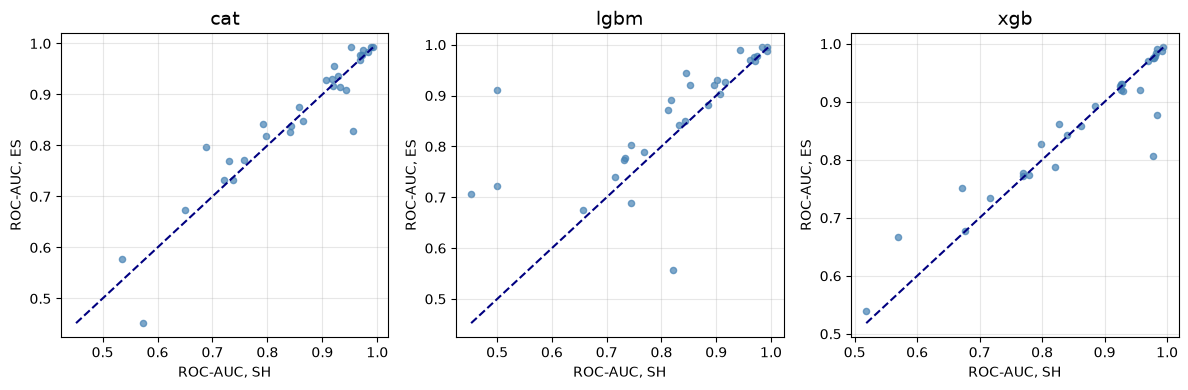

In [8]:
plot_roc(us_sh, us_es, "ROC-AUC, SH", "ROC-AUC, ES", f"../figures/{US}_expanded_es_vs_sh.png")

### Conclusion: ES vs SH after CNN

Early stopping improves `lgbm` after CNN, but not `cat` or `xgb`:

- **`lgbm`**: ROC-AUC median +0.021, better on 24 of 30 datasets (p < 0.001), and AP improves (p = 0.047). The largest gains are on small datasets (`led7digit-0-2-4-5-6-7-8-9_vs_1` +0.41, `abalone_19` +0.25, `cleveland-0_vs_4` +0.22).
- **`cat`**: ROC-AUC median +0.008, better on 19 datasets, but not significant (p = 0.10). AP and Brier score do not change.
- **`xgb`**: no change in ROC-AUC or AP. The Brier score is marginally worse (median +0.001, p = 0.007).

On small datasets, the changes are large in both directions (e.g. `lgbm` on `glass-0-1-4-6_vs_2` -0.26), because the test sets hold few minority samples.

## 2. CNN vs no undersampling

Differences are CNN - no undersampling, with both tuned with early stopping.

In [9]:
compare(us_es, base_es)

median_diff  n_better  n_worse  n_better_beyond_std  \
metric model                                                        
roc    cat        -0.0046         7       23                    0   
       lgbm       -0.0096         6       24                    2   
       xgb        -0.0072         0       30                    0   
ap     cat        -0.0158         4       26                    0   
       lgbm       -0.0219         8       22                    0   
       xgb        -0.0150         5       25                    0   
brier  cat         0.0227         0       30                    0   
       lgbm        0.0168         4       26                    1   
       xgb         0.0182         0       30                    0   

              n_worse_beyond_std  wilcoxon_p  
metric model                                  
roc    cat                     9      0.0016  
       lgbm                   13      0.0007  
       xgb                    12      0.0000  
ap     cat                     8      0.0000  
       lgbm                   11      0.0010  
       xgb                     9      0.0000  
brier  cat                    30      0.0000  
       lgbm                   25      0.0000  
       xgb                    29      0.0000

In [10]:
roc_table(base_es, us_es, ["no US", "CNN"])

cat                          lgbm  \
                                        no US            CNN          no US   
dataset                                                                       
abalone_19                      0.862 ± 0.046  0.452 ± 0.073  0.854 ± 0.062   
coil_2000                       0.768 ± 0.017  0.769 ± 0.010  0.773 ± 0.012   
ecoli                           0.973 ± 0.022  0.955 ± 0.026  0.983 ± 0.013   
mammography                     0.941 ± 0.013  0.916 ± 0.021  0.958 ± 0.011   
oil                             0.971 ± 0.009  0.908 ± 0.036  0.946 ± 0.007   
ozone_level                     0.830 ± 0.069  0.837 ± 0.044  0.847 ± 0.046   
protein_homo                    0.995 ± 0.001  0.993 ± 0.001  0.995 ± 0.001   
satimage                        0.974 ± 0.002  0.968 ± 0.003  0.975 ± 0.004   
scene                           0.802 ± 0.034  0.733 ± 0.049  0.802 ± 0.016   
sick_euthyroid                  0.987 ± 0.010  0.987 ± 0.009  0.986 ± 0.010   
solar_flare_m0                  0.874 ± 0.059  0.875 ± 0.075  0.880 ± 0.051   
spectrometer                    0.994 ± 0.005  0.993 ± 0.005  0.978 ± 0.013   
thyroid_sick                    0.993 ± 0.002  0.992 ± 0.002  0.981 ± 0.006   
us_crime                        0.932 ± 0.023  0.936 ± 0.022  0.911 ± 0.026   
webpage                         0.983 ± 0.006  0.983 ± 0.007  0.990 ± 0.004   
wine_quality                    0.852 ± 0.017  0.827 ± 0.025  0.845 ± 0.012   
yeast_me2                       0.889 ± 0.053  0.848 ± 0.056  0.928 ± 0.017   
cleveland-0_vs_4                0.871 ± 0.125  0.796 ± 0.102  0.924 ± 0.062   
glass-0-1-4-6_vs_2              0.732 ± 0.209  0.578 ± 0.162  0.735 ± 0.198   
led7digit-0-2-4-5-6-7-8-9_vs_1  0.924 ± 0.030  0.828 ± 0.055  0.963 ± 0.014   
pima                            0.832 ± 0.029  0.819 ± 0.028  0.827 ± 0.039   
poker-8-9_vs_5                  0.897 ± 0.048  0.916 ± 0.025  0.873 ± 0.058   
diabetes130                     0.680 ± 0.006  0.673 ± 0.005  0.685 ± 0.007   
default_credit                  0.778 ± 0.007  0.772 ± 0.006  0.777 ± 0.005   
htru2                           0.975 ± 0.007  0.978 ± 0.006  0.977 ± 0.005   
credit_fraud                    0.968 ± 0.011  0.977 ± 0.004  0.980 ± 0.007   
secom                           0.754 ± 0.042  0.733 ± 0.051  0.771 ± 0.058   
bank-marketing                  0.934 ± 0.003  0.930 ± 0.002  0.933 ± 0.003   
telco                           0.845 ± 0.014  0.842 ± 0.013  0.844 ± 0.014   
adult                           0.929 ± 0.001  0.928 ± 0.001  0.931 ± 0.001   

                                                         xgb                 
                                          CNN          no US            CNN  
dataset                                                                      
abalone_19                      0.706 ± 0.082  0.834 ± 0.069  0.667 ± 0.099  
coil_2000                       0.777 ± 0.012  0.778 ± 0.013  0.778 ± 0.009  
ecoli                           0.945 ± 0.037  0.975 ± 0.022  0.877 ± 0.053  
mammography                     0.921 ± 0.022  0.945 ± 0.015  0.918 ± 0.023  
oil                             0.881 ± 0.030  0.957 ± 0.010  0.920 ± 0.021  
ozone_level                     0.904 ± 0.023  0.896 ± 0.035  0.893 ± 0.040  
protein_homo                    0.995 ± 0.001  0.996 ± 0.000  0.995 ± 0.001  
satimage                        0.970 ± 0.001  0.977 ± 0.003  0.971 ± 0.002  
scene                           0.740 ± 0.017  0.804 ± 0.033  0.773 ± 0.025  
sick_euthyroid                  0.976 ± 0.013  0.986 ± 0.011  0.985 ± 0.010  
solar_flare_m0                  0.850 ± 0.081  0.871 ± 0.065  0.858 ± 0.091  
spectrometer                    0.987 ± 0.007  0.995 ± 0.004  0.988 ± 0.007  
thyroid_sick                    0.996 ± 0.003  0.994 ± 0.002  0.990 ± 0.002  
us_crime                        0.921 ± 0.021  0.937 ± 0.013  0.931 ± 0.013  
webpage                         0.990 ± 0.002  0.980 ± 0.006  0.979 ± 0.008  
wine_quality                  

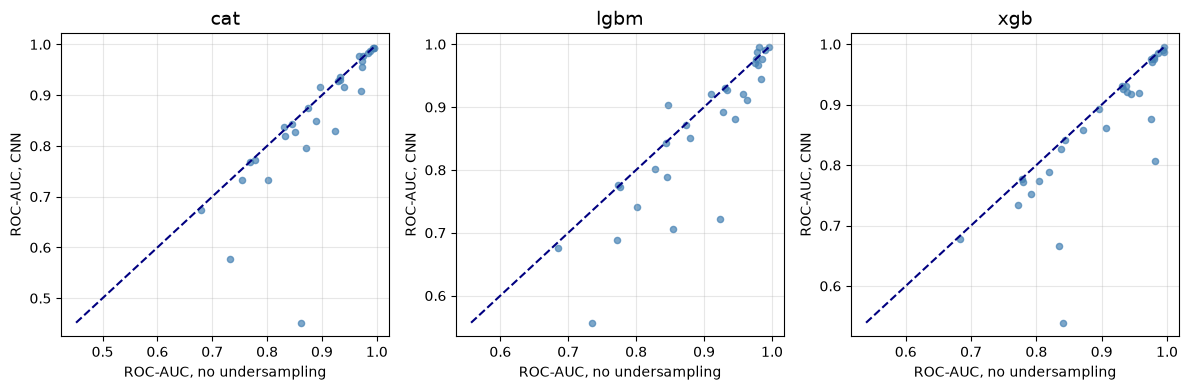

In [11]:
plot_roc(base_es, us_es, "ROC-AUC, no undersampling", "ROC-AUC, CNN", f"../figures/{US}_expanded_vs_no_us.png")

For reference, the same comparison with both tuned with successive halving (CNN - no undersampling):

In [12]:
compare(us_sh, base_sh)

median_diff  n_better  n_worse  n_better_beyond_std  \
metric model                                                        
roc    cat        -0.0129         3       27                    0   
       lgbm       -0.0222         5       25                    1   
       xgb        -0.0055         5       25                    0   
ap     cat        -0.0258         7       23                    1   
       lgbm       -0.0634         2       28                    0   
       xgb        -0.0110         7       23                    0   
brier  cat         0.0094         3       27                    1   
       lgbm        0.0203         2       28                    0   
       xgb         0.0106         2       28                    1   

              n_worse_beyond_std  wilcoxon_p  
metric model                                  
roc    cat                    11      0.0000  
       lgbm                   17      0.0002  
       xgb                    12      0.0001  
ap     cat                    12      0.0010  
       lgbm                   18      0.0000  
       xgb                     8      0.0058  
brier  cat                    20      0.0000  
       lgbm                   25      0.0000  
       xgb                    23      0.0000

### Conclusion: CNN vs no undersampling

The boosters trained after CNN are worse than the boosters trained on the original data, with or without early stopping:

- ROC-AUC is lower on 23 (`cat`), 24 (`lgbm`) and 30 (`xgb`) of 30 datasets (p ≤ 0.002). AP and Brier score are also worse.
- Only `lgbm` is better after CNN by more than the standard deviation, on 2 datasets.

Early stopping narrows the gap for `cat` (median ROC-AUC difference -0.013 with SH, -0.005 with ES) and `lgbm` (-0.022 to -0.010), but does not close it.

## Conclusions

1. Limiting the boosting rounds with early stopping improves LightGBM trained after CNN, compared with successive halving. CatBoost and XGBoost do not change significantly.
2. CNN does not make the boosters better than the same boosters trained on the imbalanced data. All three remain worse on ROC-AUC, AP and Brier score.